The Goal Here is to make 4 2D plots

Ingredients:


*   Original Particle stack 3D classificaiton job with k =2 (J439_particles)
*   3D variability Job of same particle stack (same UIDs) (J561_particles)
*   3DFlex trianing job
*   Cryodrgn training analyze folder
*   e2gmm training folder

Output:

*   2D plot of 3D Var coordinates, with uids from J439_particle classes highlighted different colors
*   2D plot of first two LD of 3DFlex, with uids from J439_particle classes highlighted different colors
*   2D plot of cryodrgn PC 1 vs PC 0, with uids from J439_particle classes highlighted different colors
*   2D plot of LD 1 vs LD 0 of e2gmm, with uids from J439_particle classes highlighted different colors
*   2D plot of PC1 1 vs PC0 of e2gmm, with uids from J439_particle classes highlighted different colors





## Get pickled UIDs from 3D Class Job

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [16]:
# Define a list of the .pkl files containing 3D class particle UIDs and their corresponding names for the legend


pkl_files = ['J439_particles_class_0_uids.pkl', 'J439_particles_class_1_uids.pkl' ]  # Replace with your actual .pkl file paths
pkl_names = ['3D Class 0 Cluster', '3D Class 1 Cluster']  # Corresponding names for the legend

Import cs file name

## Plot 1 : 3DVA 

In [20]:
#First need to import cs_file of 3DVA job
#cs_filename_3DVA = input('input name of 3DVA cs file: ')
#cs_file_3DVA = np.load(cs_filename_3DVA)  # Replace with your actual file path
cs_file_3DVA = np.load('J561_particles_exported.cs')

input the index of x_axis mode (type = int): 0
input the index of y_axis mode (type = int): 1


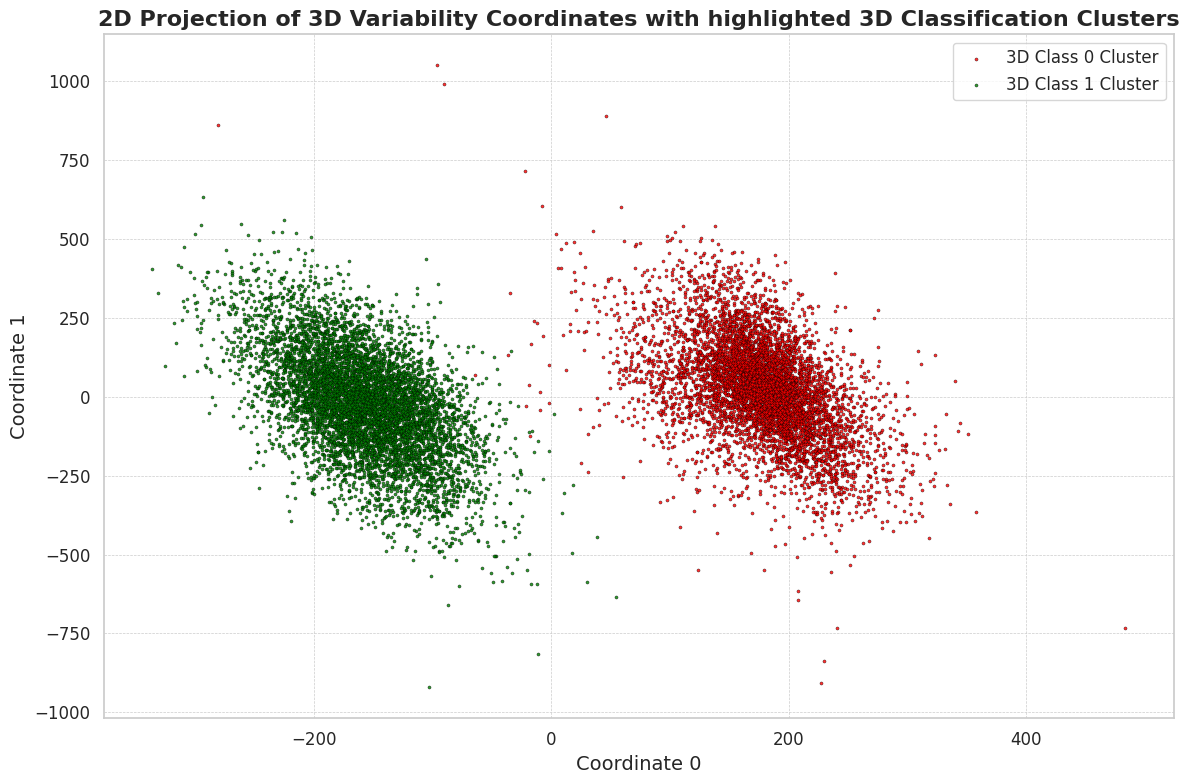

In [21]:
# Extract the coordinates and UIDs

mode_0 = input('input the index of x_axis mode (type = int): ')
mode_1 = input('input the index of y_axis mode (type = int): ')


coord0 = cs_file_3DVA[f'components_mode_{mode_0}/value']
coord1 = cs_file_3DVA[f'components_mode_{mode_1}/value']

uids = cs_file_3DVA['uid']

# Set the style for the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(12, 8))

# Plot all particles
#plt.scatter(coord0, coord1, s=5, alpha=0.6, color='blue', edgecolor='black', linewidth=0.3, label='All Particles')

# Loop through each .pkl file and plot the highlighted particles based on UIDs
colors = ['red', 'green', 'purple', 'orange', 'cyan']  # Colors for different groups
for i, pkl_file in enumerate(pkl_files):
    with open(pkl_file, 'rb') as f:
        cluster_uids = pickle.load(f)
    # Find indices where the UID in the .cs file matches the UIDs in the cluster
    cluster_indices = np.isin(uids, cluster_uids)
    plt.scatter(coord0[cluster_indices], coord1[cluster_indices], s=5, alpha=0.8, color=colors[i % len(colors)], edgecolor='black', linewidth=0.3, label=pkl_names[i])

# Add titles and labels
plt.title('2D Projection of 3D Variability Coordinates with highlighted 3D Classification Clusters', fontsize=16, fontweight='bold')
plt.xlabel('Coordinate 0', fontsize=14)
plt.ylabel('Coordinate 1', fontsize=14)

# Customize ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add a grid and tighter layout
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()

# Add a legend
plt.legend(loc='upper right', fontsize=12)

# Save the plot as a .png file in the working directory
plt.savefig(f'3DVA_{mode_1}_vs_{mode_0}_with_3D_class_clusters.png', dpi=300)  # High resolution

# Show the plot
plt.show()


## Plot 2 3D Flex


In [22]:
# Plot Latent Dimension Coords from 3DFlex cs File, and then highlight UIDs of clusters 

In [23]:
cs_file_3DFlex = np.load('J475_particles_exported.cs')

input the index of x_axis mode (type = int): 0
input the index of y_axis mode (type = int): 1


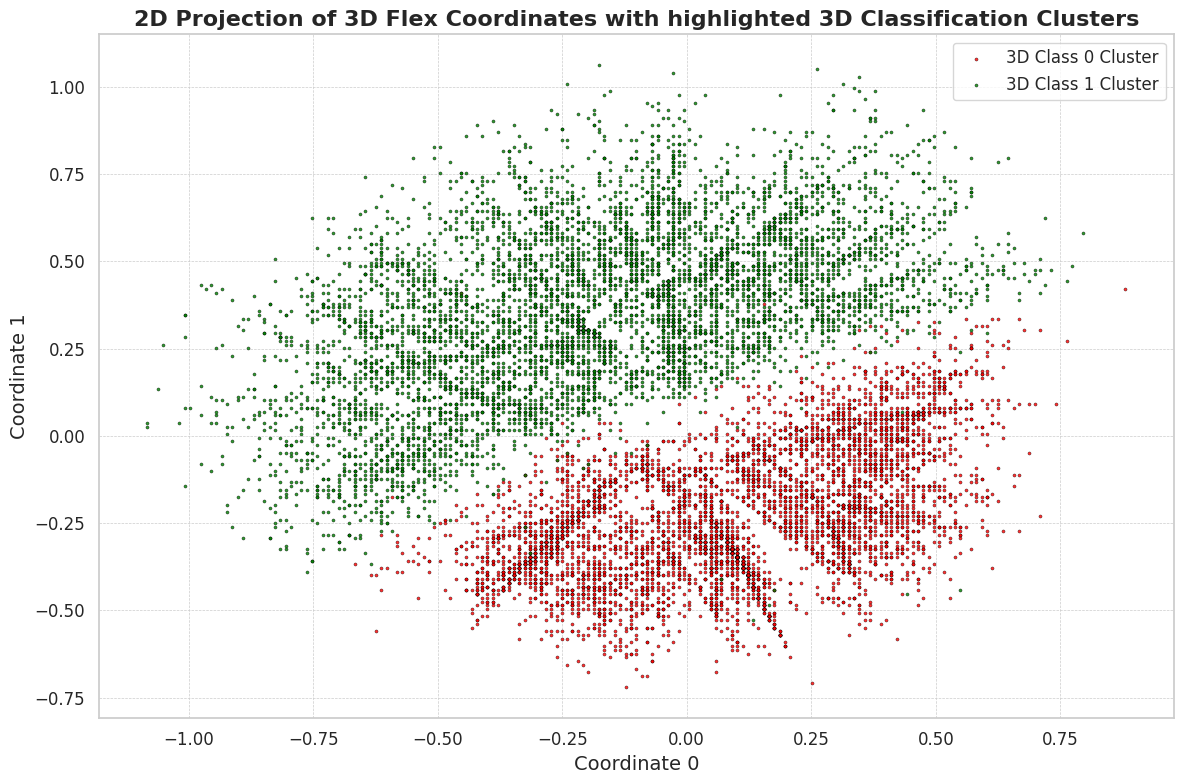

In [24]:
# Extract the coordinates and UIDs

mode_0 = input('input the index of x_axis mode (type = int): ')
mode_1 = input('input the index of y_axis mode (type = int): ')


coord0 = cs_file_3DFlex[f'components_mode_{mode_0}/value']
coord1 = cs_file_3DFlex[f'components_mode_{mode_1}/value']

uids = cs_file_3DFlex['uid']

# Set the style for the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(12, 8))

# Plot all particles
#plt.scatter(coord0, coord1, s=5, alpha=0.6, color='blue', edgecolor='black', linewidth=0.3, label='All Particles')

# Loop through each .pkl file and plot the highlighted particles based on UIDs
colors = ['red', 'green', 'purple', 'orange', 'cyan']  # Colors for different groups
for i, pkl_file in enumerate(pkl_files):
    with open(pkl_file, 'rb') as f:
        cluster_uids = pickle.load(f)
    # Find indices where the UID in the .cs file matches the UIDs in the cluster
    cluster_indices = np.isin(uids, cluster_uids)
    plt.scatter(coord0[cluster_indices], coord1[cluster_indices], s=5, alpha=0.8, color=colors[i % len(colors)], edgecolor='black', linewidth=0.3, label=pkl_names[i])

# Add titles and labels
plt.title('2D Projection of 3D Flex Coordinates with highlighted 3D Classification Clusters', fontsize=16, fontweight='bold')
plt.xlabel('Coordinate 0', fontsize=14)
plt.ylabel('Coordinate 1', fontsize=14)

# Customize ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add a grid and tighter layout
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()

# Add a legend
plt.legend(loc='upper right', fontsize=12)

# Save the plot as a .png file in the working directory
plt.savefig(f'3DFlex_{mode_1}_vs_{mode_0}_with_3D_class_clusters.png', dpi=300)  # High resolution

# Show the plot
plt.show()

## Plot 3 cryoDRGN

In [25]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

with open('z.299.pkl','rb') as f:
    latent_coordinates = pickle.load(f)
    latent_coordinates_logvar = pickle.load(f)
    


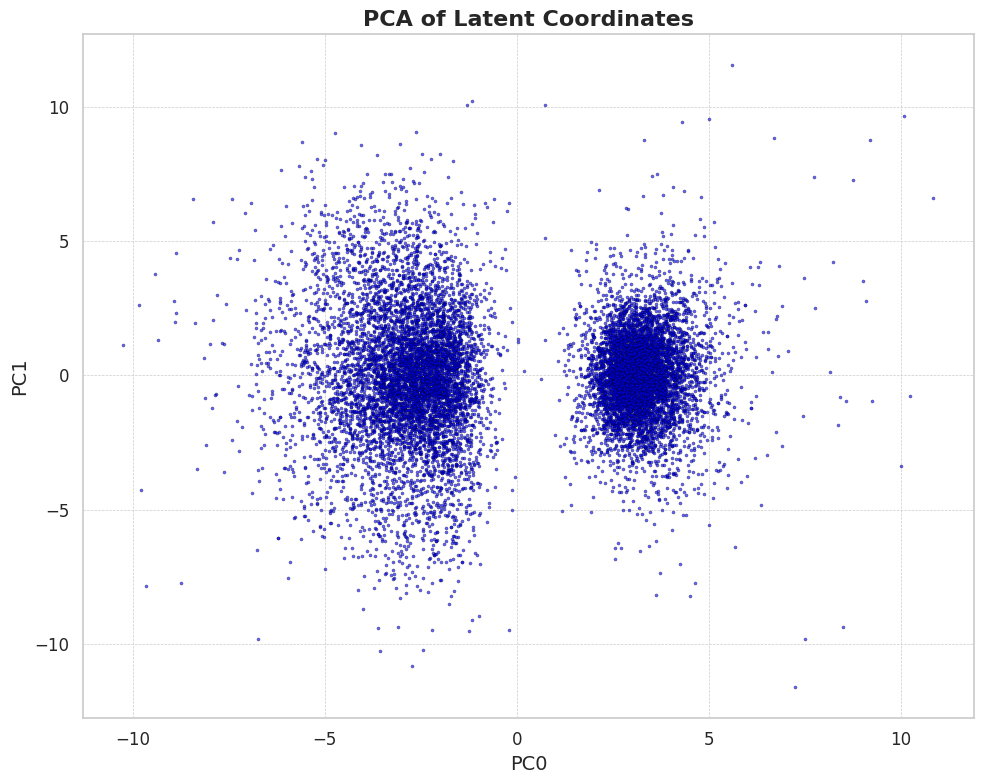

In [26]:
latent_coordinates = np.array(latent_coordinates)

# Perform PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(latent_coordinates)

# Plot the first two principal components
plt.figure(figsize=(10, 8))
plt.scatter(pca_result[:, 0], pca_result[:, 1], s=5, alpha=0.6, color='blue', edgecolor='black', linewidth=0.3)

# Add titles and labels
plt.title('PCA of Latent Coordinates', fontsize=16, fontweight='bold')
plt.xlabel('PC0', fontsize=14)
plt.ylabel('PC1', fontsize=14)

# Customize ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add a grid and tighter layout
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()

# Save the plot as a .png file in the working directory
plt.savefig('PCA_latent_coordinates.png', dpi=300)  # High resolution

# Show the plot
plt.show()

In [30]:
def load_pkl(file_path):
    with open(file_path, 'rb') as file:
        return pickle.load(file)

# Load the latent coordinates, uids, and cluster uids
latent_coords = load_pkl('z.299.pkl')  # Replace with your actual file path
cryodrgn_uids = load_pkl('J439_particle_uids.pkl')  # Load UIDs from .pkl file
cluster1_uids = load_pkl('J439_particles_class_0_uids.pkl') 
cluster2_uids = load_pkl('J439_particles_class_1_uids.pkl')  


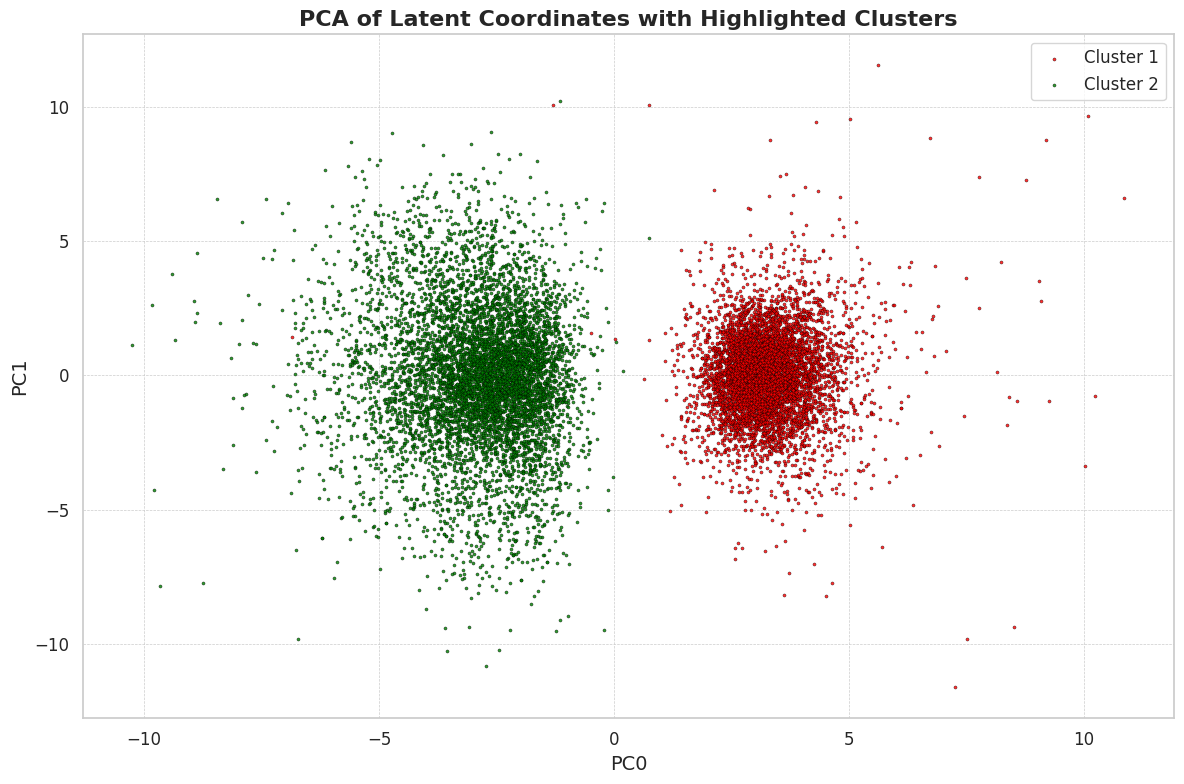

In [31]:
def map_uids_to_latent_coordinates(uids, latent_coords, uid_map):
    uid_to_latent = {}
    for uid, coords in zip(uid_map, latent_coords):
        uid_to_latent[uid] = coords
    return uid_to_latent

def plot_pca_with_highlight(latent_coords, uids, cluster1_uids, cluster2_uids):
    # Run PCA on latent coordinates
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(latent_coords)

    # Map uids to PCA coordinates
    uid_to_pca = map_uids_to_latent_coordinates(uids, pca_result, uids)

    # Prepare the data for plotting
    all_x = [uid_to_pca[uid][0] for uid in uids]
    all_y = [uid_to_pca[uid][1] for uid in uids]

    cluster1_x = [uid_to_pca[uid][0] for uid in cluster1_uids if uid in uid_to_pca]
    cluster1_y = [uid_to_pca[uid][1] for uid in cluster1_uids if uid in uid_to_pca]

    cluster2_x = [uid_to_pca[uid][0] for uid in cluster2_uids if uid in uid_to_pca]
    cluster2_y = [uid_to_pca[uid][1] for uid in cluster2_uids if uid in uid_to_pca]

    # Set the style for the plot
    sns.set(style="whitegrid")

    # Create the plot
    plt.figure(figsize=(12, 8))

    # Plot all particles
    #plt.scatter(all_x, all_y, s=5, alpha=0.6, color='blue', edgecolor='black', linewidth=0.3, label='All Particles')

    # Plot the highlighted clusters
    plt.scatter(cluster1_x, cluster1_y, s=5, alpha=0.8, color='red', edgecolor='black', linewidth=0.3, label='Cluster 1')
    plt.scatter(cluster2_x, cluster2_y, s=5, alpha=0.8, color='green', edgecolor='black', linewidth=0.3, label='Cluster 2')

    # Add titles and labels
    plt.title('PCA of Latent Coordinates with Highlighted Clusters', fontsize=16, fontweight='bold')
    plt.xlabel('PC0', fontsize=14)
    plt.ylabel('PC1', fontsize=14)

    # Customize ticks
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    # Add a grid and tighter layout
    plt.grid(True, linestyle='--', linewidth=0.5)
    plt.tight_layout()

    # Add a legend
    plt.legend(loc='upper right', fontsize=12)

    # Save the plot as a .png file in the working directory
    plt.savefig('PCA_latent_coordinates_with_highlighted_clusters.png', dpi=300)  # High resolution

    # Show the plot
    plt.show()
    

# Plot PCA with highlighted clusters
plot_pca_with_highlight(latent_coords, cryodrgn_uids, cluster1_uids, cluster2_uids)


### Plot 4 (e2gmm)

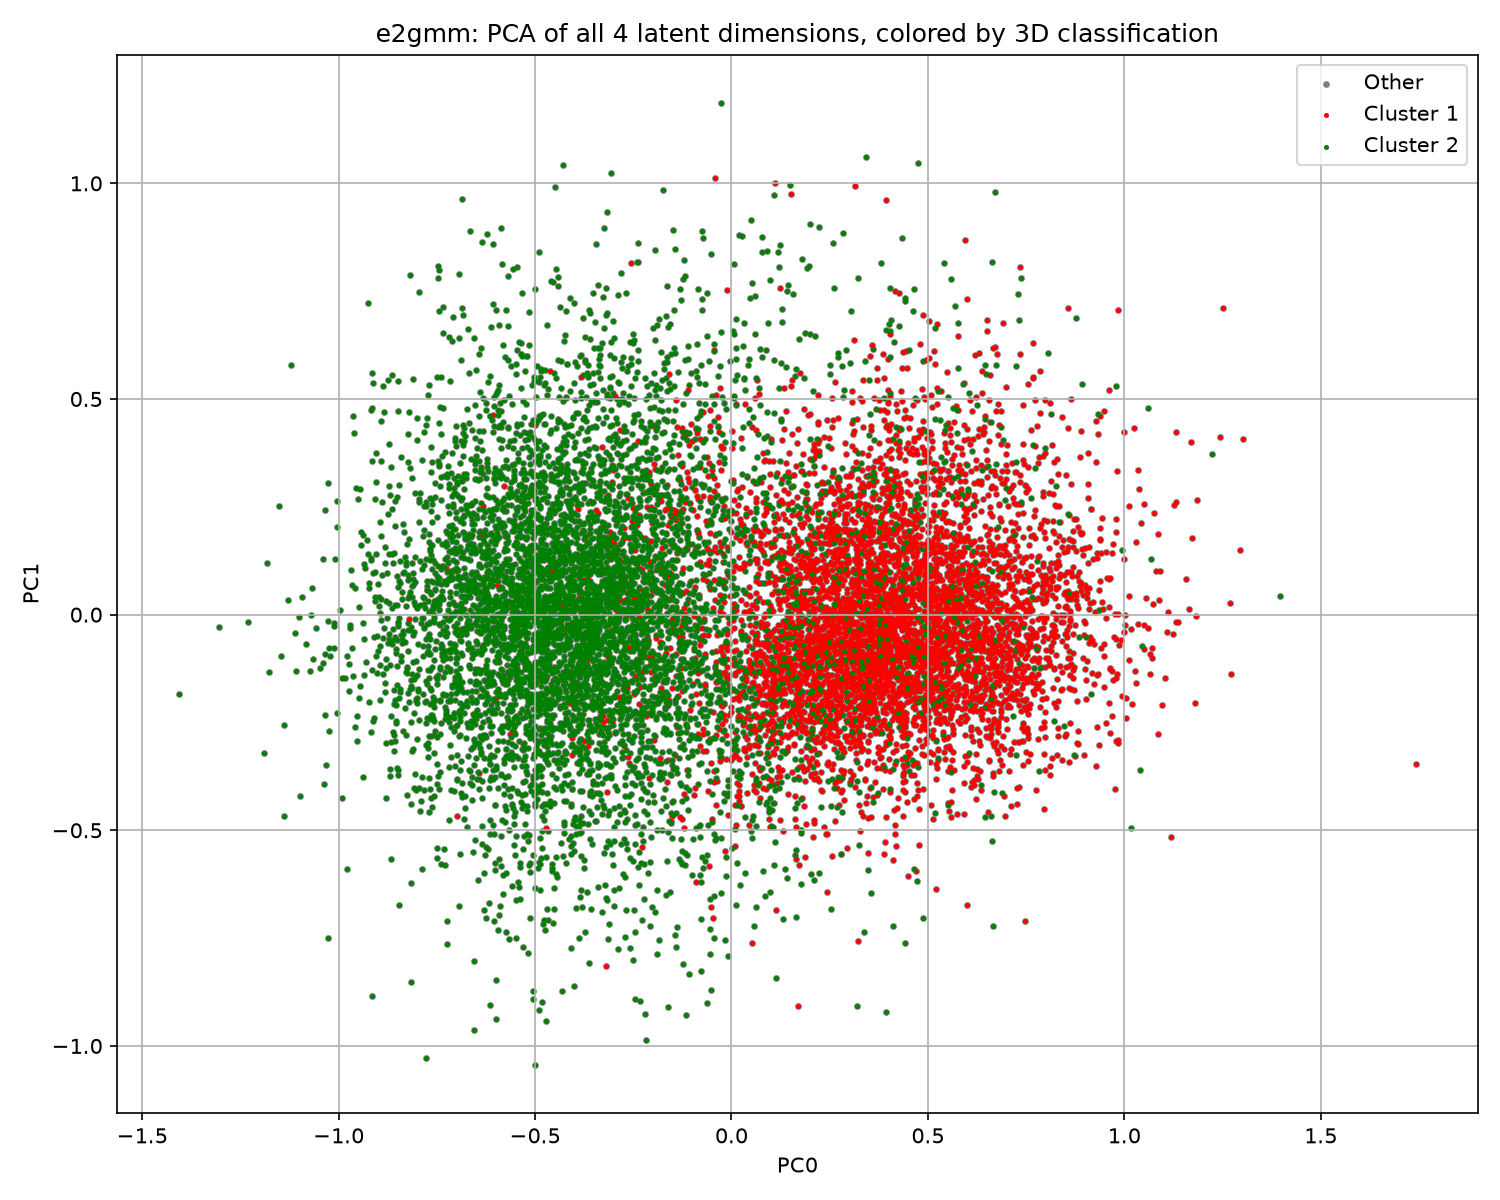

In [ ]:
# Load ALL 4 latent coordinates from the .txt file (column 0 is the particle index).
# (An earlier version read only columns 1-2, i.e. 2 of the 4 latent dimensions.)
def load_data(file_path):
    data = np.loadtxt(file_path, delimiter='\t', usecols=range(1, 5))
    return data

# Load UIDs from .pkl files
def load_uids(pkl_path):
    with open(pkl_path, 'rb') as f:
        uids = pickle.load(f)
    return uids

# Run PCA on the data
def run_pca(data, n_components=2):
    pca = PCA(n_components=n_components)
    pca_result = pca.fit_transform(data)
    return pca_result

# Plot PC1 vs. PC0 with highlighted clusters
def plot_pca_with_clusters(pca_result, uids, cluster1_uids, cluster2_uids):
    plt.figure(figsize=(10, 8))
    cluster1_mask = np.isin(uids, cluster1_uids)
    cluster2_mask = np.isin(uids, cluster2_uids)
    plt.scatter(pca_result[:, 0], pca_result[:, 1], s=5, color='gray', label='Other')
    plt.scatter(pca_result[cluster1_mask, 0], pca_result[cluster1_mask, 1], s=2, color='red', label='Cluster 1')
    plt.scatter(pca_result[cluster2_mask, 0], pca_result[cluster2_mask, 1], s=2, color='green', label='Cluster 2')
    plt.xlabel('PC0')
    plt.ylabel('PC1')
    plt.title('e2gmm: PCA of all 4 latent dimensions, colored by 3D classification')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

latent_coords_path = '5_0.3_10_100_4LD_mid.txt'  # model params: e2gmm_3/J642_particles/gmm_02
uids = load_uids('J642_uids.pkl')
cluster1_uids = load_uids('J439_particles_class_0_uids.pkl')
cluster2_uids = load_uids('J439_particles_class_1_uids.pkl')
data = load_data(latent_coords_path)
pca_result = run_pca(data)
plot_pca_with_clusters(pca_result, uids, cluster1_uids, cluster2_uids)

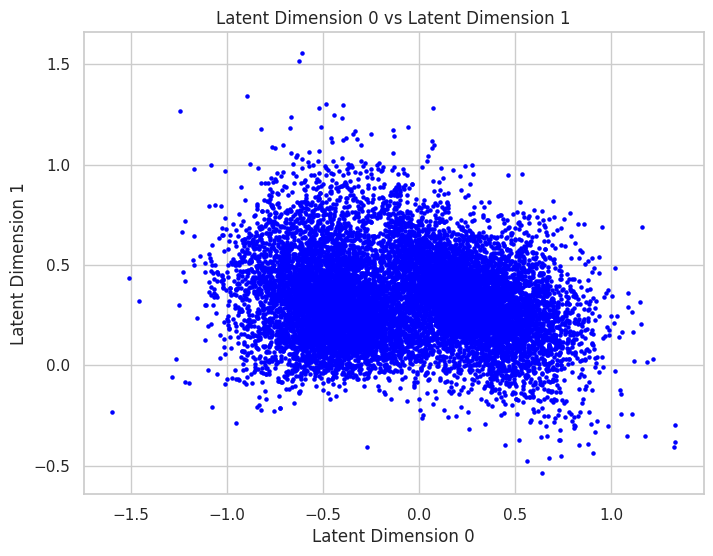

In [33]:
# Load the 4D latent coordinates from the .txt file
def load_data(file_path):
    data = np.loadtxt(file_path, delimiter='\t', usecols=range(1, 3))
    return data

# Plot latent dimension 0 vs. latent dimension 1
def plot_latent_dims(data):
    plt.figure(figsize=(8, 6))
    plt.scatter(data[:, 0], data[:, 1], s=5, color='blue')
    plt.xlabel('Latent Dimension 0')
    plt.ylabel('Latent Dimension 1')
    plt.title('Latent Dimension 0 vs Latent Dimension 1')
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    # Specify the path to your .txt file
    #file_path ='35_10_100_mid.txt'
    #file_path = '5_0.3_10_100_mid.txt'
    file_path = '5_0.3_10_100_4LD_mid.txt'
    

    # Load the data
    data = load_data(file_path)

    # Plot the latent dimensions
    plot_latent_dims(data)